[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[![VGI](assets/vgi-logo.png)](https://query.farm/vgi/)

# Reconstruct bowling economy, one delivery at a time

Can a ball-by-ball table reproduce the bowling scorecard? Two details matter: a delivery attempt is not always a legal ball, and some team runs are not charged to the bowler. We reconcile the full match first, then investigate how the same distinction affects a selected phase.

**Recorded public data:** the complete Cricsheet JSON for IPL final **1535465**, played **31 May 2026**, was retrieved on **14 November 2026 at 05:58 UTC**. It is served locally as a deliberately incomplete, one-match archive through the worker’s supported endpoint override. This is real match data, not a synthetic scorecard. The worker parses and derives the rows; the visible SQL performs the reconciliation and comparison.

Data: [Cricsheet](https://cricsheet.org/), under [ODC-By 1.0](https://opendatacommons.org/licenses/by/1-0/). The unchanged match bytes, source URL, retrieval time and SHA-256 are in [data/provenance.json](data/provenance.json).

## Choose the phase

`START_OVER` is an integer from 1 to 20, inclusive; it retains that over through the end of each regular innings. Default **1** covers the whole match. Both innings remain in the comparison, and an unfinished over keeps its actual legal-ball count. `DATA_MODE="recorded"` uses the saved match; `"live"` retrieves the public IPL archive again, without disk-cache fallback. Live data may be corrected upstream. Restart and run all after changing a parameter.

In [1]:
START_OVER = 1  # inclusive, 1–20; experiment: 16
DATA_MODE = "recorded"  # "recorded" or "live"

In [2]:
import os
from datetime import UTC, datetime

import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from notebook_support import COLORS, finish, prose, theme
from recorded_api import start_replay

if type(START_OVER) is not int or not 1 <= START_OVER <= 20:
    raise ValueError("START_OVER must be an integer between 1 and 20.")
if DATA_MODE not in ("recorded", "live"):
    raise ValueError('DATA_MODE must be "recorded" or "live".')
for name in (
    "CRICKET_CRICSHEET_BASE_URL",
    "CRICKET_ESPN_SITE_BASE_URL",
    "CRICKET_ESPN_WEB_BASE_URL",
    "CRICKET_ICC_BASE_URL",
    "CRICKET_ECB_BASE_URL",
):
    os.environ.pop(name, None)
os.environ["CRICKET_CACHE_DIR"] = "off"
replay = start_replay() if DATA_MODE == "recorded" else None
if replay:
    os.environ["CRICKET_CRICSHEET_BASE_URL"] = f"http://127.0.0.1:{replay.server_port}"
run_utc = datetime.now(UTC).isoformat(timespec="seconds")
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-cricket/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-cricket/notebooks/pyproject.toml.

## Connect to the published worker

The literal command pins a public Git revision and SDK version. It works from this notebook folder without installing the worker checkout. Recorded mode serves only the one selected match; it must not be used for season-wide totals. Live mode contacts Cricsheet and has no replay fallback. See the [README](README.md) for prerequisites and the recording boundary.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'cricket' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --with vgi-python==0.51.1 --from git+https://github.com/Query-farm/vgi-cricket@fb372ed20bdc9918501ee78f7ca61a00f484c1ae vgi-cricket'
);

,Success


## Read the deliveries and the comparison card

Materialize each worker result before displaying or plotting it. The worker reuses its in-process archive cache across these calls. The deliveries retain wides, no-balls and extras; the scorecard provides a separately exposed aggregation of the same source, not independent external ground truth.

In [4]:
%%sql
CREATE TABLE delivery_source AS
SELECT * FROM cricket.main.deliveries('ipl', match_id := 1535465);
CREATE TABLE bowling_card AS
SELECT * FROM cricket.main.bowling_scorecard('ipl', match_id := 1535465);
CREATE TABLE innings_card AS
SELECT * FROM cricket.main.innings_summary('ipl', match_id := 1535465);
SELECT innings_number, batting_team, runs, wickets, legal_balls, overs, super_over
FROM innings_card ORDER BY innings_number;

,innings_number,batting_team,runs,wickets,legal_balls,overs,super_over
0,1,Gujarat Titans,155,8,120,20.0,False
1,2,Royal Challengers Bengaluru,161,5,108,18.0,False


In [5]:
prose(
    f"Run mode: **{DATA_MODE}**; kernel started at **{run_utc}**. "
    "The match has six-ball overs. The scorecard’s `overs` is cricket notation: "
    "for example, `3.4` means 3 overs plus 4 legal balls, **not 3.4 decimal overs**. "
    "All rates below use integer legal-ball counts directly."
)

Run mode: **recorded**; kernel started at **2026-11-14T06:04:09+00:00**. The match has six-ball overs. The scorecard’s `overs` is cricket notation: for example, `3.4` means 3 overs plus 4 legal balls, **not 3.4 decimal overs**. All rates below use integer legal-ball counts directly.

## Make both parts of the rate explicit

For this six-ball format, bowling economy is **6 × (bat runs + wides + no-ball runs) / legal balls**. Byes, leg byes and penalty runs are not charged to the bowler. A wide or no-ball still contributes a delivery row but does not consume a legal ball. This notebook reads those meanings from the worker’s documented columns.

We exclude super overs, retain all other attempts, and use the stable bowler ID with innings number as the aggregation key. Full-match reconciliation happens before the phase filter, so the experiment cannot accidentally compare a partial spell with a full card.

In [6]:
%%sql
CREATE TABLE balls AS
SELECT *, runs_batter + wides + no_balls AS charged_runs,
       byes + leg_byes + penalty AS uncharged_runs
FROM delivery_source WHERE NOT super_over;
CREATE TABLE full_bowling AS
SELECT innings_number, bowler_id, min(bowler) AS bowler,
       count(*) AS attempts, count(*) FILTER (WHERE is_legal) AS legal_balls,
       sum(charged_runs) AS charged_runs,
       6.0 * sum(charged_runs) / nullif(count(*) FILTER (WHERE is_legal), 0) AS economy
FROM balls GROUP BY innings_number, bowler_id;
CREATE TABLE reconciliation AS
SELECT coalesce(a.innings_number, b.innings_number) AS innings_number,
       coalesce(a.bowler_id, b.bowler_id) AS bowler_id,
       a.bowler, a.attempts, a.legal_balls, b.legal_balls AS card_legal_balls,
       a.charged_runs, b.runs_conceded AS card_charged_runs,
       round(a.economy, 2) AS sql_economy, b.economy AS card_economy,
       a.legal_balls = b.legal_balls AND a.charged_runs = b.runs_conceded
           AND abs(a.economy - b.economy) <= 0.005001 AS agrees
FROM full_bowling a FULL OUTER JOIN bowling_card b
    ON a.innings_number = b.innings_number AND a.bowler_id = b.bowler_id;

,Count


In [7]:
%%sql reconciliation <<
SELECT innings_number, bowler, attempts, legal_balls, charged_runs, sql_economy, card_economy, agrees
FROM reconciliation ORDER BY innings_number, bowler;

In [8]:
display(reconciliation)

,innings_number,bowler,attempts,legal_balls,charged_runs,sql_economy,card_economy,agrees
0,1,B Kumar,24,24,29.0,7.25,7.25,True
1,1,JA Duffy,27,24,38.0,9.50,9.50,True
2,1,JR Hazlewood,25,24,37.0,9.25,9.25,True
3,1,KH Pandya,24,24,23.0,5.75,5.75,True
4,1,Rasikh Salam,24,24,27.0,6.75,6.75,True
5,2,Arshad Khan,24,24,32.0,8.00,8.00,True
6,2,JO Holder,12,12,16.0,8.00,8.00,True
7,2,K Rabada,18,18,44.0,14.67,14.67,True
8,2,M Prasidh Krishna,6,6,7.0,7.00,7.00,True
9,2,Mohammed Siraj,25,24,36.0,9.00,9.00,True


## Check conservation and the comparison grain

Each bowler must have an ID and consistent name; every delivery key must be unique. The runs components and legal-ball flag must agree. Reconstructed totals must match the innings card, and the full bowling card must reconcile within its two-decimal rounding. If an upstream correction introduces unsupported structure, these checks stop the notebook instead of quietly drawing an incompatible comparison.

In [9]:
%%sql checks <<
SELECT 'unique delivery keys' AS check_name,
       count(*) = count(DISTINCT (innings_number, over_number, ball_in_over)) AS passed FROM balls
UNION ALL SELECT 'known bowler IDs', count(*) > 0 AND count(bowler_id) = count(*) FROM balls
UNION ALL SELECT 'one name per bowler ID', NOT EXISTS (
    SELECT 1 FROM balls GROUP BY innings_number, bowler_id HAVING count(DISTINCT bowler) <> 1)
UNION ALL SELECT 'run components conserved', bool_and(runs_total = charged_runs + uncharged_runs) FROM balls
UNION ALL SELECT 'legal-ball flag agrees', bool_and(is_legal = (wides = 0 AND no_balls = 0)) FROM balls
UNION ALL SELECT 'full bowling card agrees', count(*) > 0 AND bool_and(coalesce(agrees, false)) FROM reconciliation
UNION ALL SELECT 'innings totals agree', count(*) > 0 AND bool_and(coalesce(
    a.runs = b.runs AND a.legal_balls = b.legal_balls, false))
FROM (SELECT innings_number, sum(runs_total) AS runs,
      count(*) FILTER (WHERE is_legal) AS legal_balls FROM balls GROUP BY innings_number) a
FULL OUTER JOIN (SELECT * FROM innings_card WHERE NOT super_over) b USING (innings_number);

In [10]:
display(checks)
assert checks.passed.fillna(False).all(), "Source assumptions or scorecard reconciliation failed."
prose(
    f"All **{len(checks)} checks** pass. SQL reproduces **{len(reconciliation)} bowling-card rows**, "
    "including legal-ball counts, charged runs and rounded economy. This validates the reconstruction "
    "against the worker’s card; it does not independently audit Cricsheet’s original scoring."
)

,check_name,passed
0,unique delivery keys,True
1,known bowler IDs,True
2,one name per bowler ID,True
3,run components conserved,True
4,legal-ball flag agrees,True
5,full bowling card agrees,True
6,innings totals agree,True


All **7 checks** pass. SQL reproduces **11 bowling-card rows**, including legal-ball counts, charged runs and rounded economy. This validates the reconstruction against the worker’s card; it does not independently audit Cricsheet’s original scoring.

## Select the phase and quantify both shortcuts

Now apply the requested over boundary. `team_rate_per_attempt` deliberately uses team runs and every row; it is a diagnostic shortcut, not bowling economy. We also keep the intermediate charged-runs-per-attempt rate so numerator and denominator effects remain distinguishable. NULL protects a zero-legal-ball denominator. Exposure counts stay beside every rate.

In [11]:
%%sql
CREATE TABLE phase AS
SELECT innings_number, bowler_id, min(bowler) AS bowler, min(bowling_team) AS bowling_team,
       count(*) AS attempts, count(*) FILTER (WHERE is_legal) AS legal_balls,
       count(*) FILTER (WHERE NOT is_legal) AS extra_attempts,
       sum(runs_total) AS team_runs, sum(charged_runs) AS charged_runs,
       sum(uncharged_runs) AS uncharged_runs,
       6.0 * sum(charged_runs) / nullif(count(*) FILTER (WHERE is_legal), 0) AS economy,
       6.0 * sum(charged_runs) / count(*) AS charged_rate_per_attempt,
       6.0 * sum(runs_total) / count(*) AS team_rate_per_attempt
FROM balls WHERE over_number >= {{START_OVER}}
GROUP BY innings_number, bowler_id;

,Count


In [12]:
%%sql phase <<
SELECT * FROM phase ORDER BY innings_number, bowler;

In [13]:
display(phase.round(3))

,innings_number,bowler_id,bowler,bowling_team,attempts,legal_balls,extra_attempts,team_runs,charged_runs,uncharged_runs,economy,charged_rate_per_attempt,team_rate_per_attempt
0,1,2e81a32d,B Kumar,Royal Challengers Bengaluru,24,24,0,29.0,29.0,0.0,7.250,7.250,7.250
1,1,dadbdb68,JA Duffy,Royal Challengers Bengaluru,27,24,3,39.0,38.0,1.0,9.500,8.444,8.667
2,1,03806cf8,JR Hazlewood,Royal Challengers Bengaluru,25,24,1,37.0,37.0,0.0,9.250,8.880,8.880
3,1,5b8c830e,KH Pandya,Royal Challengers Bengaluru,24,24,0,23.0,23.0,0.0,5.750,5.750,5.750
4,1,b8527c3d,Rasikh Salam,Royal Challengers Bengaluru,24,24,0,27.0,27.0,0.0,6.750,6.750,6.750
5,2,12314277,Arshad Khan,Gujarat Titans,24,24,0,32.0,32.0,0.0,8.000,8.000,8.000
6,2,0f721006,JO Holder,Gujarat Titans,12,12,0,16.0,16.0,0.0,8.000,8.000,8.000
7,2,e62dd25d,K Rabada,Gujarat Titans,18,18,0,44.0,44.0,0.0,14.667,14.667,14.667
8,2,85e0cf10,M Prasidh Krishna,Gujarat Titans,6,6,0,7.0,7.0,0.0,7.000,7.000,7.000
9,2,2f49c897,Mohammed Siraj,Gujarat Titans,25,24,1,37.0,36.0,1.0,9.000,8.640,8.880


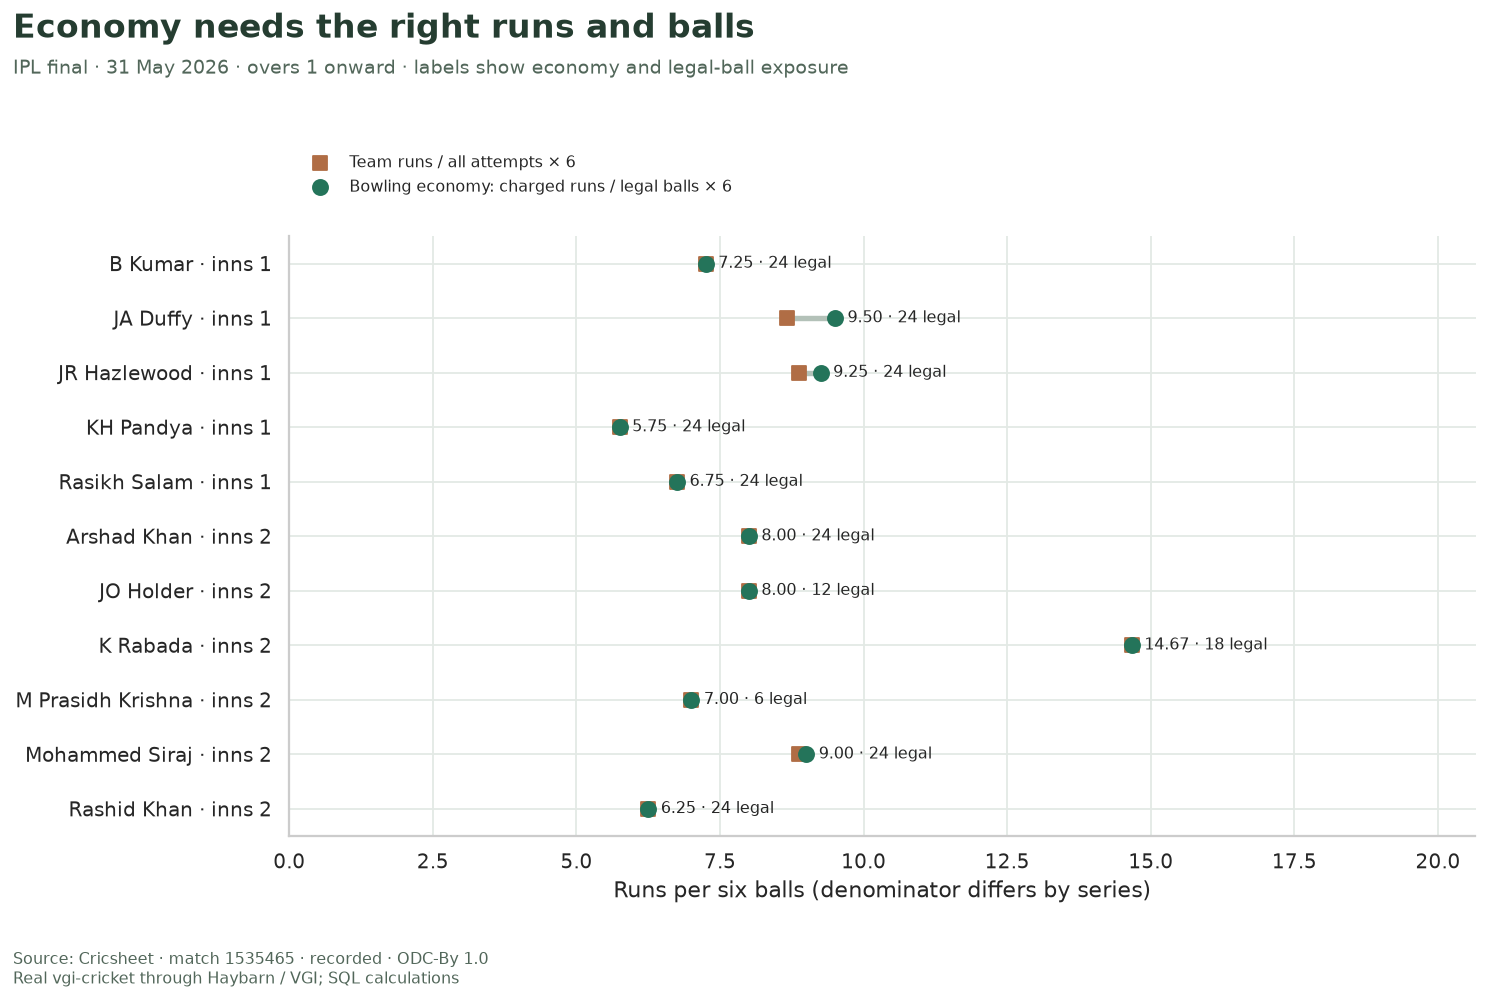

In [14]:
if phase.empty or phase.economy.isna().any():
    raise ValueError("Selected phase has no observations or a bowler has no legal balls; choose an earlier START_OVER.")
phase["label"] = phase.bowler + " · inns " + phase.innings_number.astype(str)
fig, ax = plt.subplots(figsize=(12.5, max(6.5, 0.42 * len(phase) + 3.2)))
y = np.arange(len(phase))
ax.hlines(y, phase.team_rate_per_attempt, phase.economy, color="#b3c1b8", linewidth=3)
ax.scatter(
    phase.team_rate_per_attempt,
    y,
    color=COLORS["naive"],
    s=60,
    marker="s",
    label="Team runs / all attempts × 6",
    zorder=3,
)
ax.scatter(
    phase.economy, y, color=COLORS["charged"], s=70, label="Bowling economy: charged runs / legal balls × 6", zorder=4
)
for i, row in phase.iterrows():
    ax.text(
        max(row.economy, row.team_rate_per_attempt) + 0.22,
        i,
        f"{row.economy:.2f} · {int(row.legal_balls)} legal",
        va="center",
        fontsize=9,
    )
ax.set_yticks(y, phase.label)
ax.invert_yaxis()
ax.set_xlabel("Runs per six balls (denominator differs by series)")
ax.set_xlim(0, max(phase.economy.max(), phase.team_rate_per_attempt.max()) * 1.34 + 1)
ax.legend(loc="upper left", bbox_to_anchor=(0, 1.16), frameon=False, fontsize=9)
fig.subplots_adjust(left=0.24, right=0.97, bottom=0.17, top=0.76)
finish(
    fig,
    "Economy needs the right runs and balls",
    f"IPL final · 31 May 2026 · overs {START_OVER} onward · labels show economy and legal-ball exposure",
    f"economy-{DATA_MODE}-{START_OVER}.png",
    DATA_MODE,
)

In [15]:
largest = phase.loc[(phase.economy - phase.team_rate_per_attempt).abs().idxmax()]
difference = largest.economy - largest.team_rate_per_attempt
prose(
    f"From over **{START_OVER}**, **{len(phase)} bowler-innings** contribute "
    f"**{int(phase.attempts.sum())} attempts** and **{int(phase.legal_balls.sum())} legal balls**. "
    f"The largest absolute shortcut difference belongs to **{largest.bowler}**, innings "
    f"**{int(largest.innings_number)}**: economy **{largest.economy:.2f}**, versus "
    f"**{largest.team_rate_per_attempt:.2f}** using team runs and all attempts "
    f"(economy minus shortcut **{difference:+.2f} runs per six**). "
    "Coincident markers mean the rates agree, possibly because two errors offset; "
    "agreement alone does not validate the formula."
)

From over **1**, **11 bowler-innings** contribute **233 attempts** and **228 legal balls**. The largest absolute shortcut difference belongs to **JA Duffy**, innings **1**: economy **9.50**, versus **8.67** using team runs and all attempts (economy minus shortcut **+0.83 runs per six**). Coincident markers mean the rates agree, possibly because two errors offset; agreement alone does not validate the formula.

## See where the discrepancy comes from

The left panel counts delivery attempts removed from the economy denominator. The right counts team runs excluded from its numerator. Their units differ, so they use separate axes. No claim about bowler quality follows from this single match or a short phase; opponents, match situation and sample size are uncontrolled.

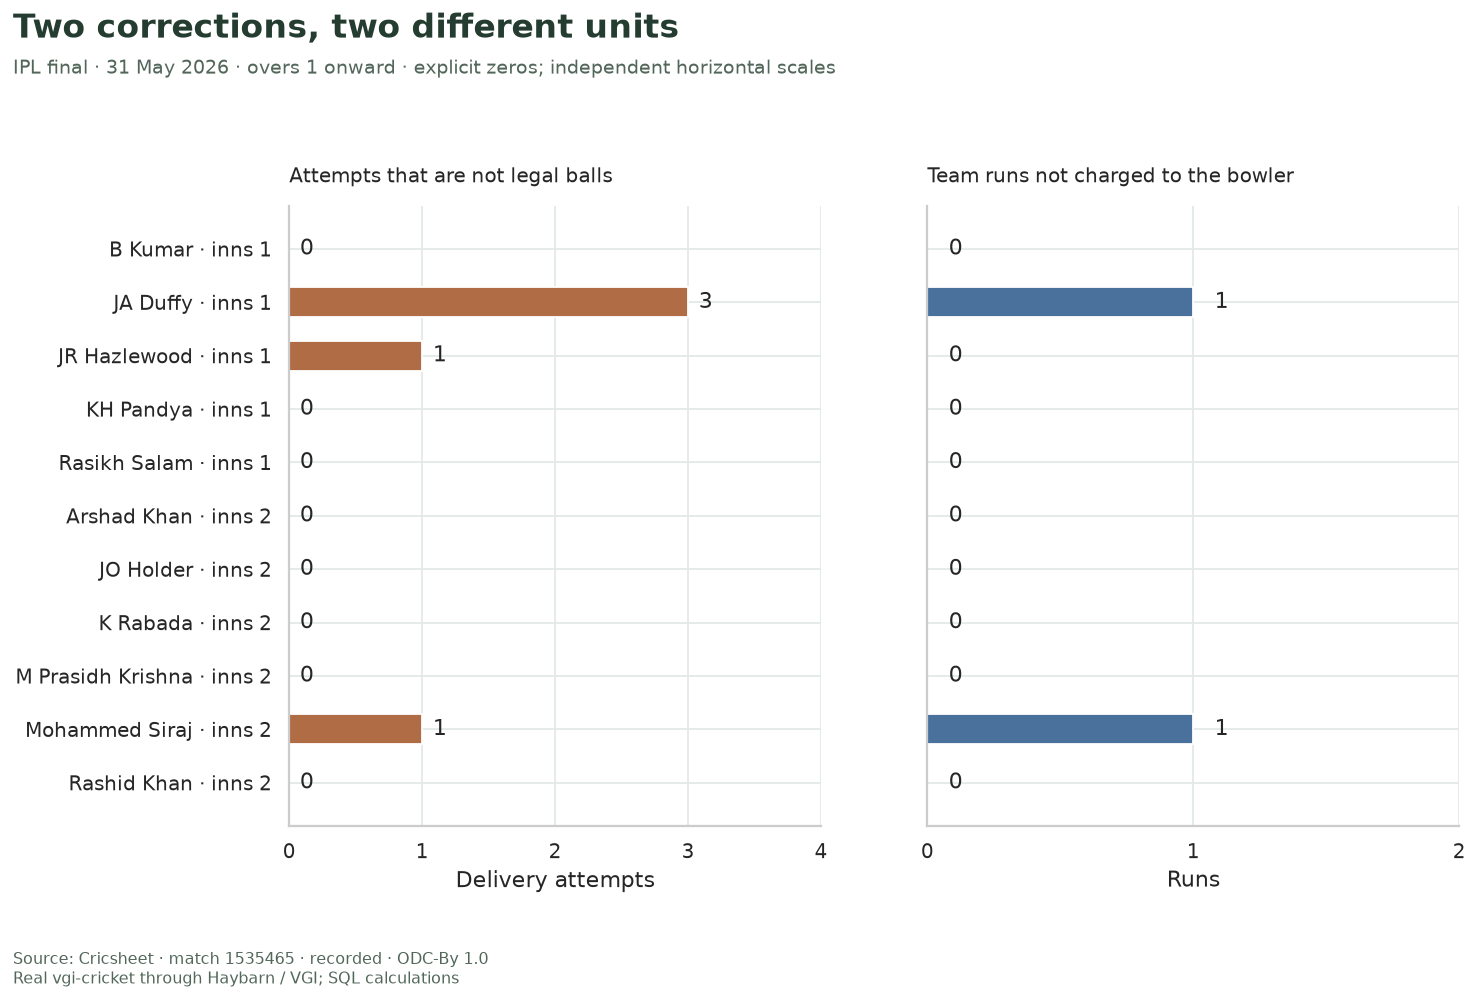

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, max(6.5, 0.42 * len(phase) + 3.2)), sharey=True)
y = np.arange(len(phase))
for ax, column, color, title, unit in [
    (axes[0], "extra_attempts", COLORS["naive"], "Attempts that are not legal balls", "Delivery attempts"),
    (axes[1], "uncharged_runs", COLORS["excluded"], "Team runs not charged to the bowler", "Runs"),
]:
    ax.barh(y, phase[column], color=color, height=0.56)
    for i, value in enumerate(phase[column]):
        ax.text(value + 0.08, i, str(int(value)), va="center")
    ax.set_xlim(0, max(phase[column].max(), 1) + 1)
    ax.set_xlabel(unit)
    ax.set_title(title, fontsize=11, loc="left", pad=13)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[0].set_yticks(y, phase.label)
axes[0].invert_yaxis()
fig.subplots_adjust(left=0.24, right=0.96, bottom=0.18, top=0.79, wspace=0.20)
finish(
    fig,
    "Two corrections, two different units",
    f"IPL final · 31 May 2026 · overs {START_OVER} onward · explicit zeros; independent horizontal scales",
    f"components-{DATA_MODE}-{START_OVER}.png",
    DATA_MODE,
)

In [17]:
prose(
    f"In the selected phase, **non-legal attempts: {int(phase.extra_attempts.sum())}**; "
    f"**runs not charged to bowlers: {int(phase.uncharged_runs.sum())}**. "
    "Adding uncharged runs raises the numerator; counting non-legal attempts raises the denominator. "
    "The two shortcuts therefore move the rate in opposite directions, and their net effect depends on the spell."
)

In the selected phase, **non-legal attempts: 5**; **runs not charged to bowlers: 2**. Adding uncharged runs raises the numerator; counting non-legal attempts raises the denominator. The two shortcuts therefore move the rate in opposite directions, and their net effect depends on the spell.

## Experiment: isolate overs 16 onward

Change only `START_OVER` from **1 to 16**, restart, and run all. Predict that fewer legal balls and bowler-innings remain; do not predict that economy must rise or that the same bowler has the largest shortcut error. Compare the exposure labels, both correction panels and the largest-gap paragraph. The full-match scorecard checks should still pass because reconciliation precedes filtering.

These are different observed phases of one match, not a controlled experiment on bowling ability. Restore **1** to recover the default. The README includes a command that saves this experiment separately; changing `DATA_MODE` is a separate source-refresh check.

In [18]:
connection.close()
if replay:
    replay.shutdown()
    replay.server_close()
os.environ.pop("CRICKET_CRICSHEET_BASE_URL", None)

'http://127.0.0.1:56967'

[![Query.Farm](assets/query-farm-strata-sun.svg)](https://query.farm/)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · Data attribution: [Cricsheet](https://cricsheet.org/)